In [60]:
import tensorflow as tf
print(tf.__version__)

2.21.0


In [61]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from PIL import Image
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras import layers, models
from tensorflow.keras.models import Model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, BatchNormalization, Activation
from tensorflow.keras.layers import MaxPooling2D, GlobalAveragePooling2D
from tensorflow.keras.layers import Dense, Dropout

In [62]:
import random
random.seed(0)
import numpy as np
np.random.seed(0)
import tensorflow as tf
tf.random.set_seed(0)

In [63]:
# dataset paths
train_df = r"C:\Users\Niharika rawat\OneDrive\Desktop\dataset\chest_xray\train"
test_df = r"C:\Users\Niharika rawat\OneDrive\Desktop\dataset\chest_xray\test"
val_df = r"C:\Users\Niharika rawat\OneDrive\Desktop\dataset\chest_xray\val"

# verify dataset structure
print("Train classes:", os.listdir(train_df))
print("Test classes:", os.listdir(test_df))
print("Validation classes:", os.listdir(val_df))

Train classes: ['NORMAL', 'PNEUMONIA']
Test classes: ['NORMAL', 'PNEUMONIA']
Validation classes: ['NORMAL', 'PNEUMONIA']


In [64]:
path = r'C:\Users\Niharika rawat\OneDrive\Desktop\dataset\chest_xray'
image_path_dict = {}  # Create image path dictionary

for split in ['train', 'test', 'val']:
    split_path = os.path.join(path, split)

    for root, dirs, files in os.walk(split_path):
        for f in files:
            if f.lower().endswith('.jpeg'):
                full_path = os.path.join(root, f)
                image_path_dict[f] = full_path

print("Total images:",len(image_path_dict))

Total images: 5856


In [65]:
pneu_df = pd.DataFrame(list(image_path_dict.items()),columns=['image_name', 'image_path'])

pneu_df.head()
pneu_df.shape

(5856, 2)

In [66]:
pneu_df['image_path'].iloc[0]

'C:\\Users\\Niharika rawat\\OneDrive\\Desktop\\dataset\\chest_xray\\train\\NORMAL\\IM-0115-0001.jpeg'

In [67]:
print("Rows:", len(pneu_df))
print("Unique paths:", pneu_df['image_path'].nunique())
print("Duplicate paths:", pneu_df['image_path'].duplicated().sum())

Rows: 5856
Unique paths: 5856
Duplicate paths: 0


In [68]:
print(pneu_df.columns)

Index(['image_name', 'image_path'], dtype='object')


In [69]:
pneu_df

,image_name,image_path
0,IM-0115-0001.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...
1,IM-0117-0001.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...
2,IM-0119-0001.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...
3,IM-0122-0001.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...
4,IM-0125-0001.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...
...,...,...
5851,person1949_bacteria_4880.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...
5852,person1950_bacteria_4881.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...
5853,person1951_bacteria_4882.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...
5854,person1952_bacteria_4883.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...


In [70]:
pneu_df['label'] = pneu_df['image_path'].apply(lambda x:1 if 'PNEUMONIA' in x else 0)  #labeling

In [71]:
pneu_df['label'].value_counts()

label
1    4273
0    1583
Name: count, dtype: int64

In [72]:
pneu_df.tail()

,image_name,image_path,label
5851,person1949_bacteria_4880.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1
5852,person1950_bacteria_4881.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1
5853,person1951_bacteria_4882.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1
5854,person1952_bacteria_4883.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1
5855,person1954_bacteria_4886.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1


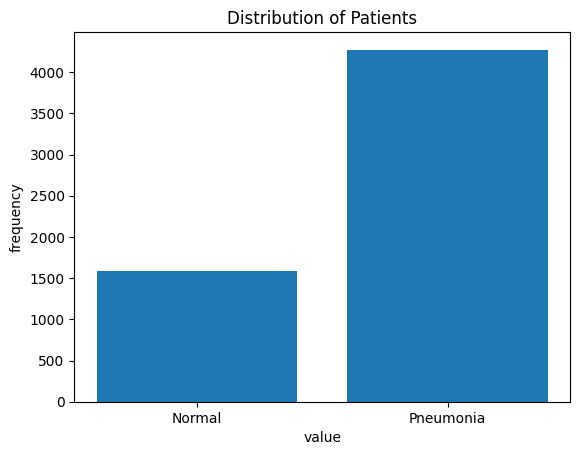

In [73]:
data = pneu_df['label'].value_counts()

plt.bar(data.index, data.values)

plt.xlabel("value")
plt.ylabel("frequency")
plt.title("Distribution of Patients")
plt.xticks([0, 1], ["Normal", "Pneumonia"])
plt.show()

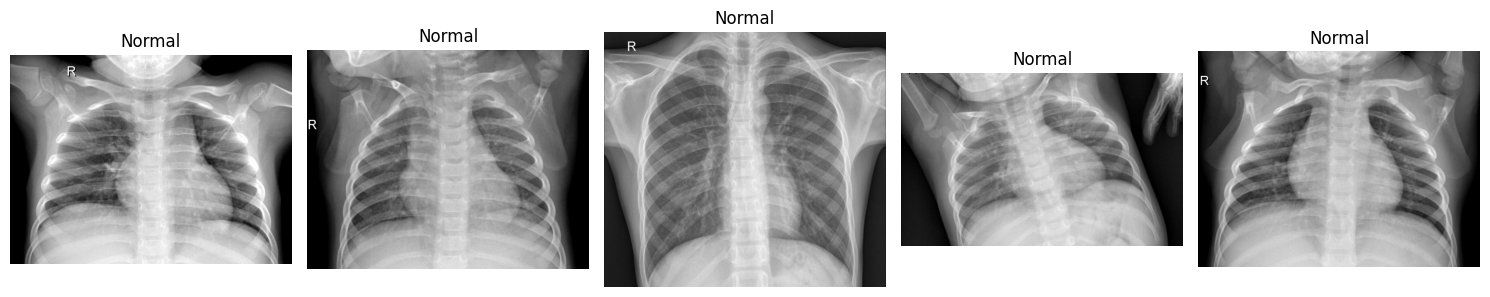

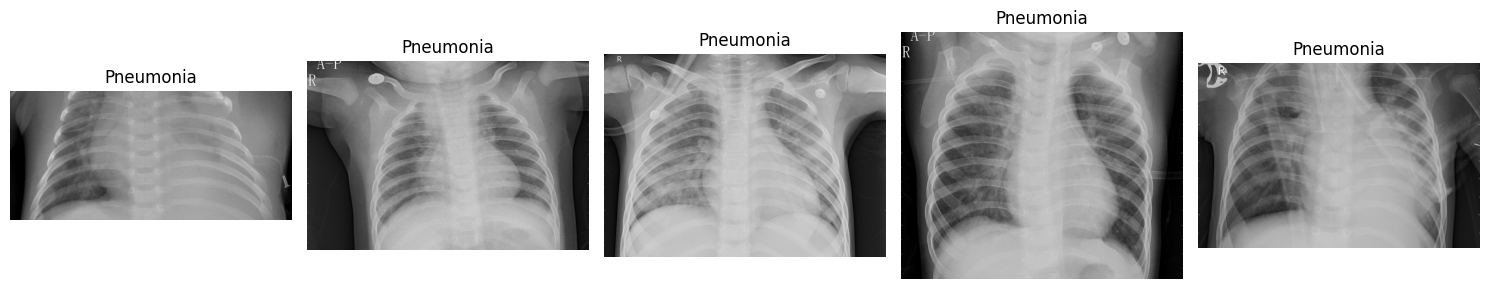

In [74]:
normal_images = pneu_df[pneu_df['label']==0]['image_path'].sample(5, random_state=42)
pneumonia_images = pneu_df[pneu_df['label']==1]['image_path'].sample(5, random_state=42)

plt.figure(figsize=(15, 5))
for i, img_path in enumerate(normal_images):
    img = Image.open(img_path)

    plt.subplot(1, 5, i + 1)
    plt.imshow(img, cmap='gray')
    plt.axis('off')
    plt.title('Normal')

plt.tight_layout()
plt.show()


plt.figure(figsize=(15, 5))
for i, img_path in enumerate(pneumonia_images):
    img = Image.open(img_path)

    plt.subplot(1, 5, i + 1)
    plt.imshow(img, cmap='gray')
    plt.axis('off')
    plt.title('Pneumonia')

plt.tight_layout()
plt.show()

In [75]:
pneu_df.isnull().sum()

image_name    0
image_path    0
label         0
dtype: int64

In [76]:
print("Duplicate Image Names:",pneu_df['image_name'].duplicated().sum())
print("Duplicate Image Path:",pneu_df['image_path'].duplicated().sum())

Duplicate Image Names: 0
Duplicate Image Path: 0


In [77]:
corrupted = []

for path in pneu_df['image_path']:

    try:
        img = Image.open(path)
        img.verify()

    except Exception:
        corrupted.append(path)

print("Corrupted images:", len(corrupted))

Corrupted images: 0


In [78]:
corrupted = []

for path in pneu_df['image_path']:

    try:
        img = Image.open(path)
        img.verify()

    except Exception:
        corrupted.append(path)

print("Corrupted images:", len(corrupted))

Corrupted images: 0


In [79]:
train_df,temp_df = train_test_split(pneu_df,test_size = 0.2,random_state = 42,stratify = pneu_df['label'])

val_df,test_df = train_test_split(temp_df, test_size = 0.5,random_state = 42,stratify = temp_df['label'])

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 4684
Validation: 586
Test: 586


In [80]:
pneu_df

,image_name,image_path,label
0,IM-0115-0001.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,0
1,IM-0117-0001.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,0
2,IM-0119-0001.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,0
3,IM-0122-0001.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,0
4,IM-0125-0001.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,0
...,...,...,...
5851,person1949_bacteria_4880.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1
5852,person1950_bacteria_4881.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1
5853,person1951_bacteria_4882.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1
5854,person1952_bacteria_4883.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1


In [81]:
import PIL.ImageOps as ImageOps 

def processed_image(image_path):
    img=Image.open(image_path)
    img=img.convert('L')
    img = ImageOps.pad(img,(224, 224),color=0,centering=(0.5, 0.5))
    img=np.array(img)
    img=img/255.0
    img = img[..., np.newaxis]
    return img

In [82]:
sample_img = processed_image(train_df.iloc[0]['image_path'])

print(sample_img.shape)
print(sample_img.min(), sample_img.max())

(224, 224, 1)
0.0 0.8274509803921568


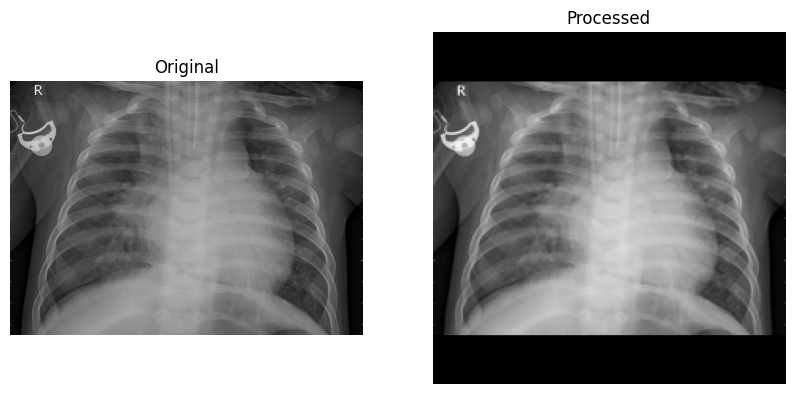

In [83]:
img_path = train_df.iloc[0]['image_path']

original = Image.open(img_path)
processed = processed_image(img_path)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(original, cmap='gray')
plt.title("Original")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(processed, cmap='gray')
plt.title("Processed")
plt.axis('off')

plt.show()

In [84]:
train_df

,image_name,image_path,label
5786,person80_bacteria_391.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1
1427,person1051_virus_1750.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1
4746,person734_bacteria_2637.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1
3695,person410_bacteria_1825.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1
1987,person1320_bacteria_3347.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1
...,...,...,...
3896,person462_bacteria_1968.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1
989,NORMAL2-IM-0944-0001.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,0
3554,person371_bacteria_1701.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1
2472,person1518_virus_2645.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1


In [85]:
#training dataset
x_train = np.array([processed_image(path)
                    for path in train_df['image_path']])
y_train = train_df['label'].values

#validation dataset
x_val = np.array([processed_image(path)
                    for path in val_df['image_path']])
y_val = val_df['label'].values

#testing dataset
x_test = np.array([processed_image(path)
                    for path in test_df['image_path']])
y_test = test_df['label'].values


print("x_train:", x_train.shape)
print("y_train:", y_train.shape)

print("x_val:", x_val.shape)
print("y_val:", y_val.shape)

print("x_test:", x_test.shape)
print("y_test:", y_test.shape)

x_train: (4684, 224, 224, 1)
y_train: (4684,)
x_val: (586, 224, 224, 1)
y_val: (586,)
x_test: (586, 224, 224, 1)
y_test: (586,)


In [86]:
print(np.unique(y_train))
print(np.unique(y_val))
print(np.unique(y_test))

[0 1]
[0 1]
[0 1]


In [87]:
sample = processed_image(train_df.iloc[0]['image_path'])
print(sample.shape)

(224, 224, 1)


In [88]:
y_train

array([1, 1, 1, ..., 1, 1, 1], shape=(4684,))

In [89]:
train_datagen = ImageDataGenerator(rotation_range = 10,
                                  zoom_range = 0.1,
                                  horizontal_flip = True,
                                  width_shift_range = 0.05,
                                  height_shift_range = 0.05)

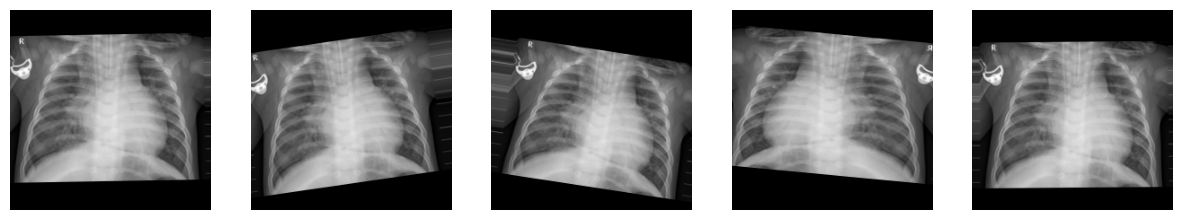

In [90]:
sample = x_train[0].reshape(1,224,224,1)
aug_iter = train_datagen.flow(sample, batch_size=1)
plt.figure(figsize=(15,5))

for i in range(5):
    aug_img = next(aug_iter)[0]
    plt.subplot(1,5,i+1)
    plt.imshow(aug_img.squeeze(), cmap='gray')
    plt.axis('off')

plt.show()

In [91]:
x_train_rgb = np.repeat(x_train, 3, axis=-1)
x_val_rgb   = np.repeat(x_val, 3, axis=-1)
x_test_rgb  = np.repeat(x_test, 3, axis=-1)

print(x_train_rgb.shape)

(4684, 224, 224, 3)


In [92]:
train_generator = train_datagen.flow(x_train_rgb,y_train,batch_size=32,shuffle=True)
val_generator = ImageDataGenerator().flow(x_val_rgb,y_val,batch_size=32)
test_generator = ImageDataGenerator().flow(x_test_rgb,y_test,batch_size=32,shuffle=False)

In [93]:
print(x_train.shape)
print(x_train_rgb.shape if 'x_train_rgb' in globals() else "Not created")

(4684, 224, 224, 1)
(4684, 224, 224, 3)


In [94]:
base_model = DenseNet121(weights='imagenet',
                         include_top=False,
                         input_shape=(224,224,3))  #loading densenet

base_model.trainable = True    #freezing pretrained layers

print(len(base_model.layers))
for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers[-10:]:
    print(layer.name, layer.trainable)
    
x = base_model.output           #adding classification head
x = GlobalAveragePooling2D()(x)

x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)

outputs = Dense(1, activation='sigmoid')(x)

model = Model(inputs=base_model.input,
              outputs=outputs)
model.summary()

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
427
conv5_block15_concat True
conv5_block16_0_bn True
conv5_block16_0_relu True
conv5_block16_1_conv True
conv5_block16_1_bn True
conv5_block16_1_relu True
conv5_block16_2_conv True
conv5_block16_concat True
bn True
relu True


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 224, 224, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ zero_padding2d                │ (None, 230, 230, 3)       │               0 │ input_layer[0][0]          │
│ (ZeroPadding2D)               │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1_conv (Conv2D)           │ (None, 112, 112, 64)      │           9,408 │ zero_padding2d[0][0]       │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1_bn (BatchNormalization) │ (None, 112, 112, 64)      │             256 │ conv1_conv[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1_relu (Activation)       │ (None, 112, 112, 64)      │               0 │ conv1_bn[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ zero_padding2d_1              │ (None, 114, 114, 64)      │               0 │ conv1_relu[0][0]           │
│ (ZeroPadding2D)               │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ pool1 (MaxPooling2D)          │ (None, 56, 56, 64)        │               0 │ zero_padding2d_1[0][0]     │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_0_bn             │ (None, 56, 56, 64)        │             256 │ pool1[0][0]                │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_0_relu           │ (None, 56, 56, 64)        │               0 │ conv2_block1_0_bn[0][0]    │
│ (Activation)                  │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_1_conv (Conv2D)  │ (None, 56, 56, 128)       │           8,192 │ conv2_block1_0_relu[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_1_bn             │ (None, 56, 56, 128)       │             512 │ conv2_block1_1_conv[0][0]  │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_1_relu           │ (None, 56, 56, 128)       │               0 │ conv2_block1_1_bn[0][0]    │
│ (Activation)                  │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_2_conv (Conv2D)  │ (None, 56, 56, 32)        │          36,864 │ conv2_block1_1_relu[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_concat           │ (None, 56, 56, 96)        │               0 │ pool1[0][0],               │
│ (Concatenate)                 │                           │               

 Total params: 7,300,161 (27.85 MB)

 Trainable params: 904,065 (3.45 MB)

 Non-trainable params: 6,396,096 (24.40 MB)

In [95]:
from tensorflow.keras.metrics import Precision,Recall,AUC
from tensorflow.keras.optimizers import Adam

model.compile(optimizer = Adam(1e-4),
             loss = 'binary_crossentropy',
             metrics=['accuracy',Precision(name='precision'),Recall(name='recall'),AUC(name='auc')])

In [96]:
import tensorflow as tf

print(tf.__version__)
print(tf.config.list_physical_devices('GPU'))

2.21.0
[]
